Project: Reducing Missed Hospital Appointments Through Data Analytics

1. Introduction

Missed hospital appointments are a challenge for healthcare facilities because they can reduce the efficient use of medical staff, appointment slots, and other hospital resources. This project uses Python and data analytics to investigate patterns in missed appointments and recommend practical improvements.

2. Problem Statement

Hospitals schedule appointments for patients, but some patients fail to attend. Without analyzing appointment records, hospital administrators may find it difficult to identify attendance patterns and prioritize improvements. This project aims to use historical data to identify factors associated with missed appointments.

3. Objectives

To load and explore a hospital appointment dataset.

To clean and transform the data using Pandas.

To calculate appointment attendance and missed-appointment rates.

To investigate relationships involving waiting time, SMS reminders, age groups, weekdays, neighbourhoods, and gender.

To develop evidence-based recommendations for improving attendance.

2. The business questions
This project will investigate eight questions:
1. What proportion of scheduled appointments are missed?
2. Is the time between booking and the appointment associated with missed attendance?
3. Is receiving an SMS reminder associated with attendance?
4. Which age groups have higher missed-appointment rates?
5. Which weekdays have higher missed-appointment rates?
6. Which neighbourhoods have higher missed-appointment rates?
7. Are missed-appointment rates different by gender?
8. Which numerical variables show relationships worth investigating?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set the visual style of our graphs
sns.set_theme(style="whitegrid")

# Create a folder for saving graphs
Path("graphs").mkdir(exist_ok=True)

# Load the dataset
df = pd.read_csv("C:\\Users\\Admin\\Desktop\\Hospital_appointment_analytic_project\\noshowappointments-kagglev2-may-2016.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


Section B: Explore and understand the data

In [2]:
# Display column names
print("Columns:")
print(df.columns.tolist())

# Display data types and non-missing values
df.info()

# Display statistical summaries
display(df.describe(include="all").T)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

Columns:
['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show']
<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PatientId,110527.0,NaN,NaN,NaN,147496265710394.0625,256094920291739.09375,39217.84439,4172614444192.0,31731838713978.0,94391720898175.0,999981631772427.0
AppointmentID,110527.0,NaN,NaN,NaN,5675305.123427,71295.75154,5030230.0,5640285.5,5680573.0,5725523.5,5790484.0
Gender,110527,2,F,71840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ScheduledDay,110527,103549,2016-05-06T07:09:54Z,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AppointmentDay,110527,27,2016-06-06T00:00:00Z,4692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,110527.0,NaN,NaN,NaN,37.088874,23.110205,-1.0,18.0,37.0,55.0,115.0
Neighbourhood,110527,81,JARDIM CAMBURI,7717,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Scholarship,110527.0,NaN,NaN,NaN,0.098266,0.297675,0.0,0.0,0.0,0.0,1.0
Hipertension,110527.0,NaN,NaN,NaN,0.197246,0.397921,0.0,0.0,0.0,0.0,1.0
Diabetes,110527.0,NaN,NaN,NaN,0.071865,0.258265,0.0,0.0,0.0,0.0,1.0



Missing values:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Duplicate rows: 0


What we are looking for:
- The number of records and variables.
- Missing values that could affect calculations.
- Duplicate records that may distort results.
- Unusual values, such as negative patient ages.
- The types of data stored in each column.
Why is this important? Data analysis is only useful when the underlying data is reliable. Incorrect dates, duplicates, or invalid ages can produce misleading conclusions.

Section C: Clean and transform the data

In [3]:
# Work on a copy of the original data
df = df.copy()

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# Standardize column names for easier coding
df = df.rename(columns={
    "PatientId": "patient_id",
    "AppointmentID": "appointment_id",
    "Gender": "gender",
    "ScheduledDay": "scheduled_day",
    "AppointmentDay": "appointment_day",
    "Age": "age",
    "Neighbourhood": "neighbourhood",
    "Scholarship": "scholarship",
    "Hipertension": "hypertension",
    "Diabetes": "diabetes",
    "Alcoholism": "alcoholism",
    "Handcap": "handicap",
    "SMS_received": "sms_received",
    "No-show": "no_show"
})

# Convert appointment dates into datetime format
df["scheduled_day"] = pd.to_datetime(
    df["scheduled_day"], errors="coerce"
)

df["appointment_day"] = pd.to_datetime(
    df["appointment_day"], errors="coerce"
)

# Remove duplicate rows
df = df.drop_duplicates()

# Remove records with invalid dates
df = df.dropna(
    subset=["scheduled_day", "appointment_day", "no_show"]
)

# Remove impossible negative ages
df = df[df["age"] >= 0]

# Standardize the no-show labels
df["no_show"] = df["no_show"].astype(str).str.strip().str.title()

# Keep only valid attendance labels
df = df[df["no_show"].isin(["Yes", "No"])]

# Calculate the waiting time in days
df["waiting_days"] = (
    df["appointment_day"].dt.normalize()
    - df["scheduled_day"].dt.normalize()
).dt.days

# Remove records where appointment dates precede scheduling dates
df = df[df["waiting_days"] >= 0]

# Create a numerical attendance indicator
df["missed"] = (df["no_show"] == "Yes").astype(int)

# Create weekday and age-group columns
df["weekday"] = df["appointment_day"].dt.day_name()

df["age_group"] = pd.cut(
    df["age"],
    bins=[-1, 17, 29, 44, 59, 120],
    labels=[
        "0–17", "18–29", "30–44", "45–59", "60+"
    ]
)

print("Rows after cleaning:", len(df))
print("Columns after cleaning:", df.shape[1])
print("Missing values after cleaning:")
print(df.isnull().sum())

Rows after cleaning: 110521
Columns after cleaning: 18
Missing values after cleaning:
patient_id         0
appointment_id     0
gender             0
scheduled_day      0
appointment_day    0
age                0
neighbourhood      0
scholarship        0
hypertension       0
diabetes           0
alcoholism         0
handicap           0
sms_received       0
no_show            0
waiting_days       0
missed             0
weekday            0
age_group          0
dtype: int64


Important limitation: Removing invalid dates and negative waiting periods is a cleaning decision. We should document how many records are removed and why. Also, identical rows are not necessarily duplicate appointments in every dataset, so in a more advanced analysis we would inspect duplicate appointment IDs before deciding what to remove.

Section D: Validate the cleaned data

In [4]:
print("Remaining duplicate rows:", df.duplicated().sum())

print("Invalid negative ages:", (df["age"] < 0).sum())

print("Negative waiting periods:", (df["waiting_days"] < 0).sum())

print("Invalid attendance labels:",
      (~df["no_show"].isin(["Yes", "No"])).sum())

print("\nCleaned data preview:")
display(df.head())

Remaining duplicate rows: 0
Invalid negative ages: 0
Negative waiting periods: 0
Invalid attendance labels: 0

Cleaned data preview:


,patient_id,appointment_id,gender,scheduled_day,appointment_day,age,neighbourhood,scholarship,hypertension,diabetes,alcoholism,handicap,sms_received,no_show,waiting_days,missed,weekday,age_group
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,0,0,Friday,60+
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,0,0,Friday,45–59
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,0,0,Friday,60+
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,0,0,Friday,0–17
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,0,0,Friday,45–59


Section E: Calculate the key performance indicators

In [5]:
total_appointments = len(df)

missed_appointments = (df["no_show"] == "Yes").sum()

attended_appointments = (df["no_show"] == "No").sum()

missed_rate = df["missed"].mean() * 100

attendance_rate = 100 - missed_rate

print("Total appointments:", total_appointments)
print("Missed appointments:", missed_appointments)
print("Attended appointments:", attended_appointments)
print(f"Missed appointment rate: {missed_rate:.2f}%")
print(f"Attendance rate: {attendance_rate:.2f}%")

Total appointments: 110521
Missed appointments: 22314
Attended appointments: 88207
Missed appointment rate: 20.19%
Attendance rate: 79.81%


Graph 1: Overall appointment outcomes

Question: How many appointments were attended and how many were missed?

Explanation: This graph gives an overview of attendance. It helps hospital management understand the scale of missed appointments.

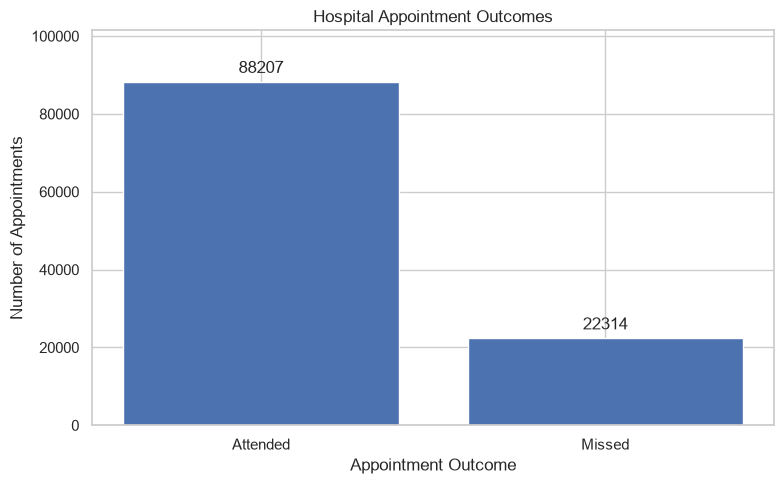

Missed appointment rate: 20.19 %


In [6]:

import matplotlib.pyplot as plt

outcomes = df["no_show"].map({
    "No": "Attended",
    "Yes": "Missed"
}).value_counts().reindex(
    ["Attended", "Missed"], fill_value=0
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(outcomes.index, outcomes.values)

ax.set_title("Hospital Appointment Outcomes")
ax.set_xlabel("Appointment Outcome")
ax.set_ylabel("Number of Appointments")

ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_ylim(0, max(outcomes.max() * 1.15, 1))

plt.tight_layout()
plt.savefig("graphs/graph1_outcomes.png", dpi=300)
plt.show()

print("Missed appointment rate:",
      round((df["no_show"] == "Yes").mean() * 100, 2), "%")


“My analysis found that the missed appointment rate was 20.19%. This means that approximately one in five scheduled appointments was missed. This is important because missed appointments can waste hospital resources and delay patient care. I recommend investigating the reasons for missed appointments and considering reminders or easier rescheduling.”

Graph 2: Waiting time versus missed-appointment rate

Question: Are appointments scheduled further in advance associated with a higher missed rate?

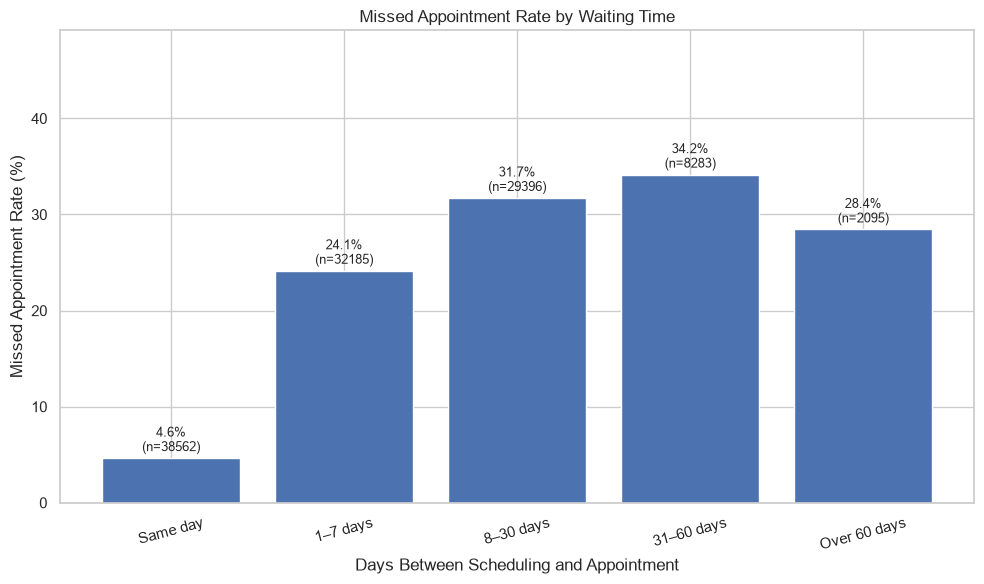

,waiting_group,appointment_count,missed_rate_percent
0,Same day,38562,4.647062
1,1–7 days,32185,24.147895
2,8–30 days,29396,31.722003
3,31–60 days,8283,34.154292
4,Over 60 days,2095,28.448687


In [7]:

import pandas as pd
import matplotlib.pyplot as plt

bins = [-1, 0, 7, 30, 60, float("inf")]
labels = [
    "Same day", "1–7 days", "8–30 days",
    "31–60 days", "Over 60 days"
]

df["waiting_group"] = pd.cut(
    df["waiting_days"],
    bins=bins,
    labels=labels
)

summary = (
    df.groupby("waiting_group", observed=False)
      .agg(
          missed_rate=("missed", "mean"),
          appointment_count=("missed", "size")
      )
      .reindex(labels)
      .reset_index()
)

summary["missed_rate_percent"] = summary["missed_rate"] * 100

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    summary["waiting_group"].astype(str),
    summary["missed_rate_percent"]
)

for bar, rate, count in zip(
    bars, summary["missed_rate_percent"],
    summary["appointment_count"]
):
    if pd.notna(rate):
        ax.annotate(
            f"{rate:.1f}%\n(n={count})",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5), textcoords="offset points",
            ha="center", fontsize=9
        )

ax.set_title("Missed Appointment Rate by Waiting Time")
ax.set_xlabel("Days Between Scheduling and Appointment")
ax.set_ylabel("Missed Appointment Rate (%)")
ax.set_ylim(0, min(100, summary["missed_rate_percent"].max() + 15))

plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("graphs/graph2_waiting_time.png", dpi=300)
plt.show()

display(summary[
    ["waiting_group", "appointment_count", "missed_rate_percent"]
])


“My analysis shows that waiting time is associated with missed appointment rates. Same-day appointments have the lowest missed rate of 4.65%, while appointments scheduled 31–60 days in advance have the highest rate of 34.15%. This suggests that patients may be more likely to miss appointments when they have to wait longer. The hospital could consider sending reminders and making rescheduling easier. However, further analysis is needed to establish the reasons behind these missed appointments.”

If longer waits are associated with more missed appointments, the hospital could investigate reminder schedules or offer earlier appointments.

Graph 3: SMS reminders and attendance

Question: Is receiving an SMS reminder associated with attendance?

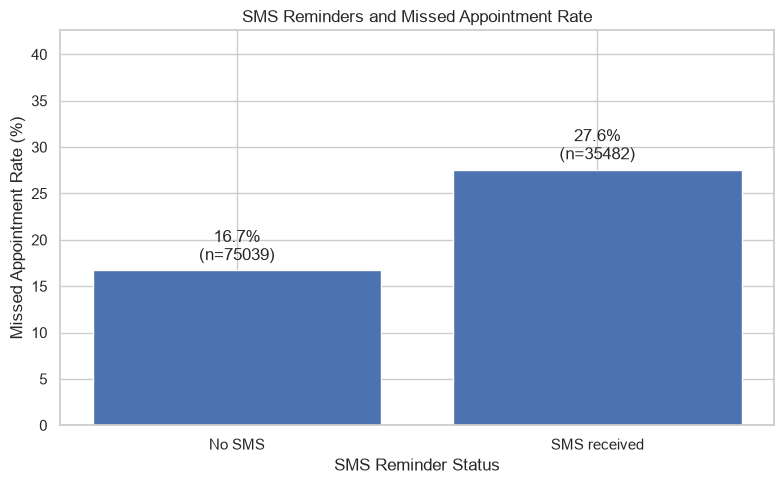

,reminder,appointment_count,missed_rate_percent
sms_received,,,
0,No SMS,75039,16.697984
1,SMS received,35482,27.574545


In [8]:

import matplotlib.pyplot as plt

sms_summary = (
    df.groupby("sms_received", observed=True)
      .agg(
          missed_rate=("missed", "mean"),
          appointment_count=("missed", "size")
      )
      .reindex([0, 1])
      .dropna(subset=["missed_rate"])
)

sms_summary["reminder"] = sms_summary.index.map({
    0: "No SMS",
    1: "SMS received"
})
sms_summary["missed_rate_percent"] = (
    sms_summary["missed_rate"] * 100
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    sms_summary["reminder"],
    sms_summary["missed_rate_percent"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.1f}%\n(n={count})"
        for rate, count in zip(
            sms_summary["missed_rate_percent"],
            sms_summary["appointment_count"]
        )
    ],
    padding=4
)

ax.set_title("SMS Reminders and Missed Appointment Rate")
ax.set_xlabel("SMS Reminder Status")
ax.set_ylabel("Missed Appointment Rate (%)")
ax.set_ylim(
    0,
    min(100, sms_summary["missed_rate_percent"].max() + 15)
)

plt.tight_layout()
plt.savefig("graphs/graph3_sms.png", dpi=300)
plt.show()

display(sms_summary[
    ["reminder", "appointment_count", "missed_rate_percent"]
])


Explanation: This compares the missed rate for appointments where an SMS was received with the rate where no SMS was received.

“My analysis found that patients who received SMS reminders had a missed appointment rate of 27.57%, compared with 16.70% for patients who did not receive SMS reminders. This was an unexpected result. It does not mean SMS reminders cause missed appointments, because other factors may influence attendance. I recommend investigating how reminders are sent and comparing similar groups of patients before deciding how to improve the reminder system.”

Business use: The hospital can use the results to decide whether to investigate its SMS reminder process. The comparison alone does not prove that SMS reminders prevent missed appointments because the two groups may differ in other ways.

Graph 4: Age groups and missed appointments

Question: Which age groups have higher missed-appointment rates?

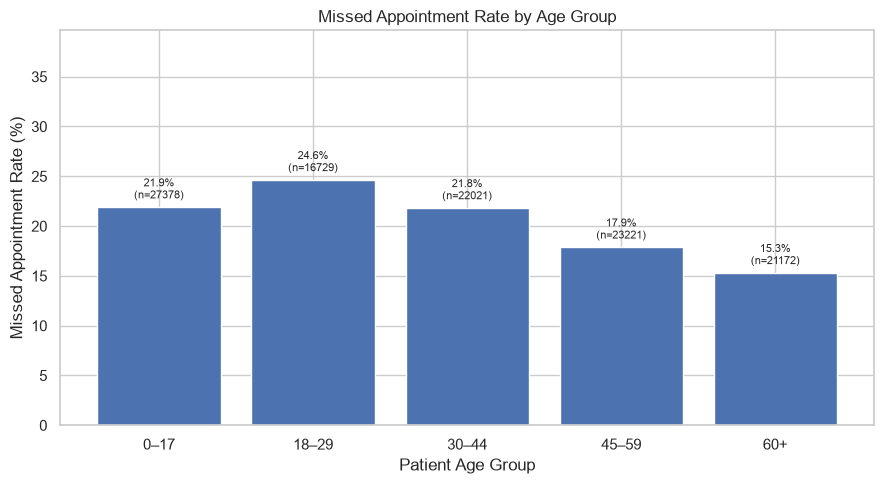

,appointment_count,missed_rate_percent
age_group,,
0–17,27378,21.900796
18–29,16729,24.639847
30–44,22021,21.820081
45–59,23221,17.871754
60+,21172,15.307954


In [9]:

import pandas as pd
import matplotlib.pyplot as plt

# Create age groups if they do not already exist
if "age_group" not in df.columns:
    df["age_group"] = pd.cut(
        df["age"],
        bins=[-1, 17, 29, 44, 59, float("inf")],
        labels=["0–17", "18–29", "30–44", "45–59", "60+"]
    )

age_order = ["0–17", "18–29", "30–44", "45–59", "60+"]

age_summary = (
    df.groupby("age_group", observed=False)
      .agg(
          missed_rate=("missed", "mean"),
          appointment_count=("missed", "size")
      )
      .reindex(age_order)
      .dropna(subset=["missed_rate"])
)

age_summary["missed_rate_percent"] = (
    age_summary["missed_rate"] * 100
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    age_summary.index.astype(str),
    age_summary["missed_rate_percent"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.1f}%\n(n={count})"
        for rate, count in zip(
            age_summary["missed_rate_percent"],
            age_summary["appointment_count"]
        )
    ],
    padding=4,
    fontsize=8
)

ax.set_title("Missed Appointment Rate by Age Group")
ax.set_xlabel("Patient Age Group")
ax.set_ylabel("Missed Appointment Rate (%)")
ax.set_ylim(
    0,
    min(100, age_summary["missed_rate_percent"].max() + 15)
)

plt.tight_layout()
plt.savefig("graphs/graph4_age_groups.png", dpi=300)
plt.show()

display(age_summary[
    ["appointment_count", "missed_rate_percent"]
])


Explanation: Grouping ages makes it easier to compare patient groups rather than examining every individual age.

Business use: If certain age groups have higher missed rates, the hospital could investigate whether appointment communication or accessibility needs differ for those groups. We should not assume the reason without further evidence.

Graph 5: Weekday and missed-appointment rate

Question: Are missed appointments more common on particular weekdays?

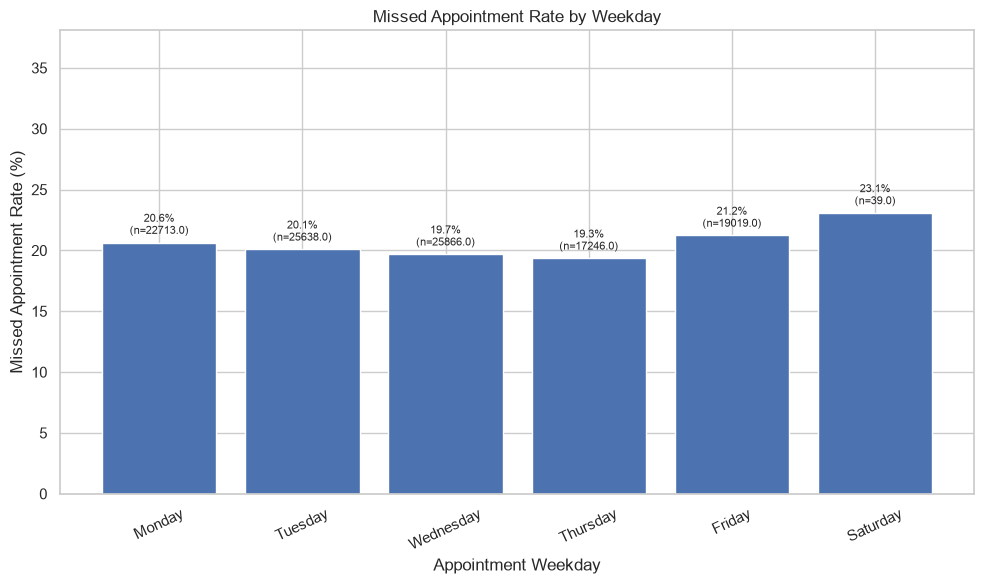

,appointment_count,missed_rate_percent
weekday,,
Monday,22713.0,20.644565
Tuesday,25638.0,20.087370
Wednesday,25866.0,19.686074
Thursday,17246.0,19.349414
Friday,19019.0,21.226142
Saturday,39.0,23.076923


In [10]:

import matplotlib.pyplot as plt

# Create weekday from the appointment date
df["weekday"] = df["appointment_day"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    df.groupby("weekday", observed=True)
      .agg(
          missed_rate=("missed", "mean"),
          appointment_count=("missed", "size")
      )
      .reindex(weekday_order)
      .dropna(subset=["missed_rate"])
)

weekday_summary["missed_rate_percent"] = (
    weekday_summary["missed_rate"] * 100
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    weekday_summary.index,
    weekday_summary["missed_rate_percent"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.1f}%\n(n={count})"
        for rate, count in zip(
            weekday_summary["missed_rate_percent"],
            weekday_summary["appointment_count"]
        )
    ],
    padding=4,
    fontsize=8
)

ax.set_title("Missed Appointment Rate by Weekday")
ax.set_xlabel("Appointment Weekday")
ax.set_ylabel("Missed Appointment Rate (%)")
ax.set_ylim(
    0,
    min(100, weekday_summary["missed_rate_percent"].max() + 15)
)

plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("graphs/graph5_weekdays.png", dpi=300)
plt.show()

display(weekday_summary[
    ["appointment_count", "missed_rate_percent"]
])


Explanation: The graph compares the percentage of appointments missed on different days, not just the raw number of missed appointments.

Business use: The hospital could review staffing, appointment availability, and patient communication on days with consistently higher missed rates.

Graph 6: Neighbourhoods and missed appointments

Question: Which neighbourhoods have higher missed rates among those with sufficient records?

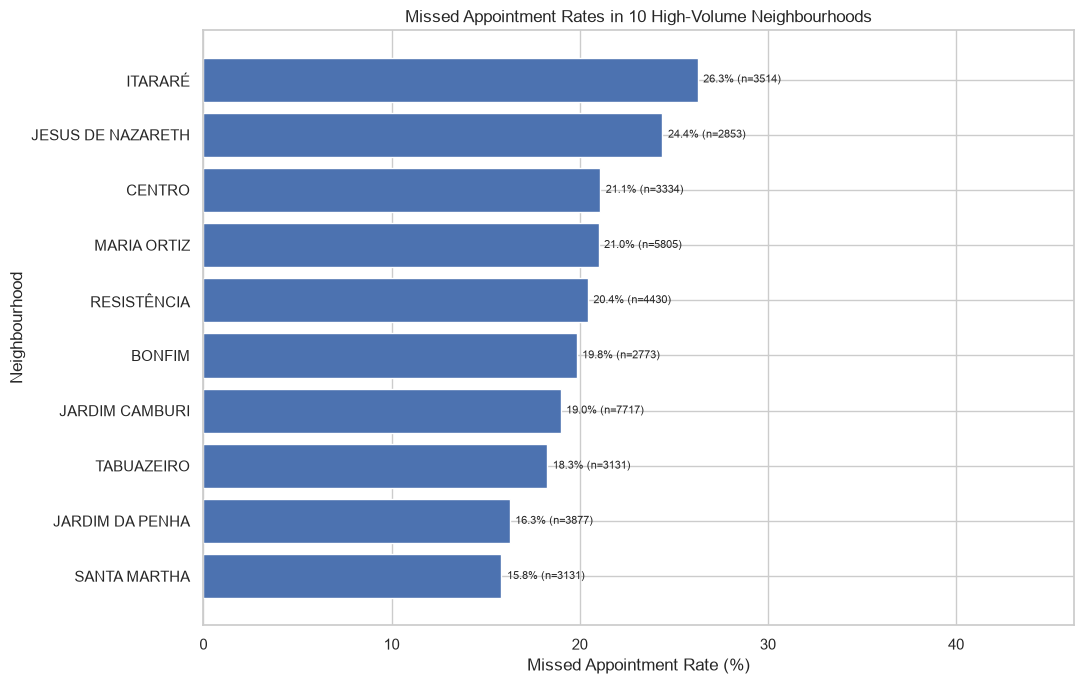

,neighbourhood,appointment_count,missed_rate_percent
66,SANTA MARTHA,3131,15.841584
39,JARDIM DA PENHA,3877,16.275471
78,TABUAZEIRO,3131,18.268924
38,JARDIM CAMBURI,7717,18.984061
8,BONFIM,2773,19.834115
59,RESISTÊNCIA,4430,20.428894
43,MARIA ORTIZ,5805,20.999139
10,CENTRO,3334,21.085783
40,JESUS DE NAZARETH,2853,24.395373
36,ITARARÉ,3514,26.266363


In [11]:

import matplotlib.pyplot as plt

neighbourhood_summary = (
    df.groupby("neighbourhood", observed=True)
      .agg(
          missed_rate=("missed", "mean"),
          appointment_count=("missed", "size")
      )
      .reset_index()
)

# Select the 10 neighbourhoods with the most appointments
top_neighbourhoods = neighbourhood_summary.nlargest(
    10, "appointment_count"
).copy()

top_neighbourhoods["missed_rate_percent"] = (
    top_neighbourhoods["missed_rate"] * 100
)

# Sort so the highest missed rate appears at the top
top_neighbourhoods = top_neighbourhoods.sort_values(
    "missed_rate_percent"
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_neighbourhoods["neighbourhood"],
    top_neighbourhoods["missed_rate_percent"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.1f}% (n={count})"
        for rate, count in zip(
            top_neighbourhoods["missed_rate_percent"],
            top_neighbourhoods["appointment_count"]
        )
    ],
    padding=4,
    fontsize=8
)

ax.set_title(
    "Missed Appointment Rates in 10 High-Volume Neighbourhoods"
)
ax.set_xlabel("Missed Appointment Rate (%)")
ax.set_ylabel("Neighbourhood")

ax.set_xlim(
    0,
    min(100, top_neighbourhoods["missed_rate_percent"].max() + 20)
)

plt.tight_layout()
plt.savefig("graphs/graph6_neighbourhoods.png", dpi=300)
plt.show()

display(top_neighbourhoods[
    ["neighbourhood", "appointment_count", "missed_rate_percent"]
])


Explanation: This graph examines the ten neighbourhoods with the highest appointment volumes. It helps us compare rates without focusing only on places with very few records.

Business use: Hospital administrators could investigate whether transport access, appointment availability, or other local factors contribute to attendance patterns. The dataset does not establish these explanations by itself.

Graph 7: Gender and missed appointments

Question: Does the missed rate differ by gender in this dataset?

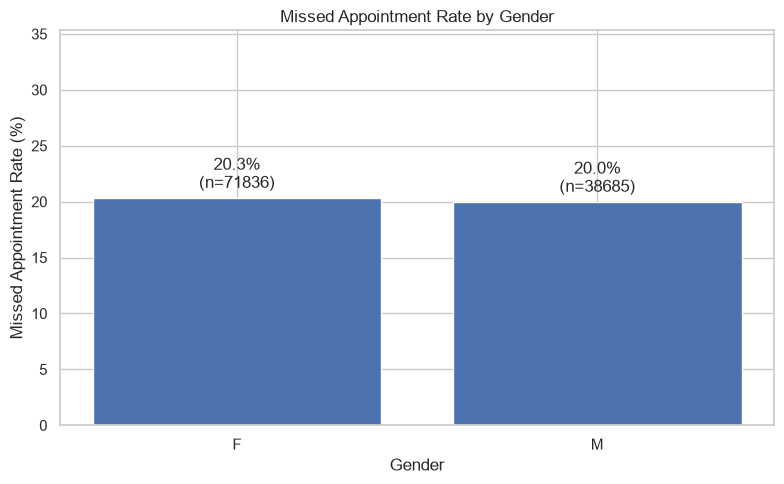

,gender,appointment_count,missed_rate_percent
0,F,71836,20.311543
1,M,38685,19.963810


In [12]:

import matplotlib.pyplot as plt

gender_summary = (
    df.groupby("gender", observed=True)
      .agg(
          missed_rate=("missed", "mean"),
          appointment_count=("missed", "size")
      )
      .reset_index()
)

gender_summary["missed_rate_percent"] = (
    gender_summary["missed_rate"] * 100
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    gender_summary["gender"].astype(str),
    gender_summary["missed_rate_percent"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.1f}%\n(n={count})"
        for rate, count in zip(
            gender_summary["missed_rate_percent"],
            gender_summary["appointment_count"]
        )
    ],
    padding=4
)

ax.set_title("Missed Appointment Rate by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Missed Appointment Rate (%)")
ax.set_ylim(
    0,
    min(100, gender_summary["missed_rate_percent"].max() + 15)
)

plt.tight_layout()
plt.savefig("graphs/graph7_gender.png", dpi=300)
plt.show()

display(gender_summary[
    ["gender", "appointment_count", "missed_rate_percent"]
])


Explanation: This compares missed-appointment rates across the gender categories present in the dataset.

Business use: Any observed difference should be interpreted carefully. Gender alone does not explain why an individual misses an appointment, and hospital policies should avoid unfair treatment.

Graph 8: Correlation heatmap

Question: How are selected numerical variables related to one another?

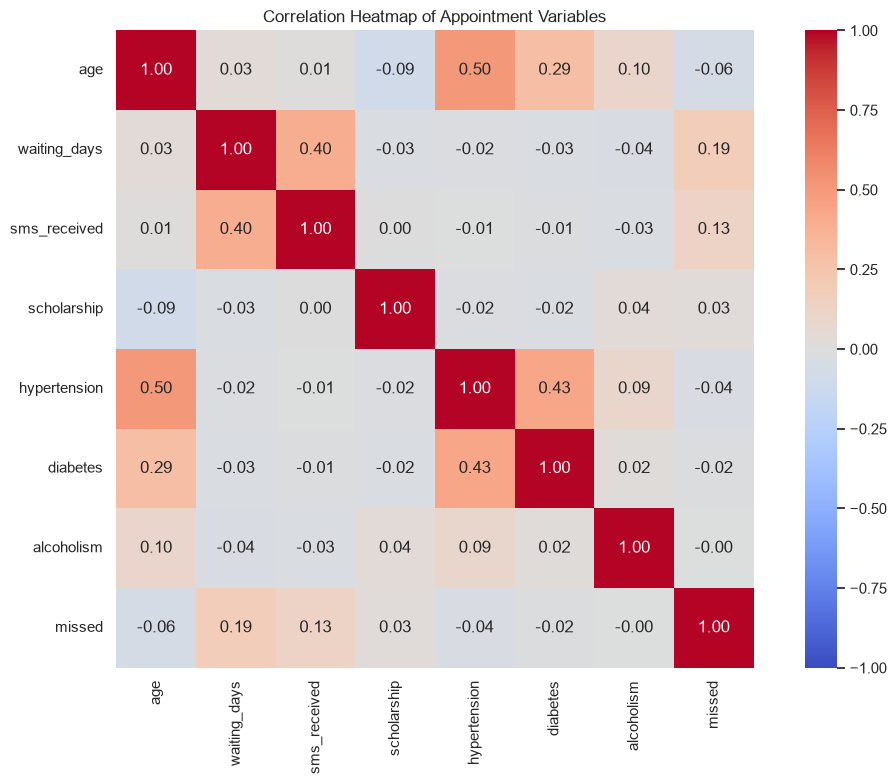

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = [
    "age",
    "waiting_days",
    "sms_received",
    "scholarship",
    "hypertension",
    "diabetes",
    "alcoholism",
    "missed"
]

# Convert selected columns to numeric where possible
numeric_data = df[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

correlation_matrix = numeric_data.corr()

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)

ax.set_title("Correlation Heatmap of Appointment Variables")

plt.tight_layout()
plt.savefig("graphs/graph8_correlation.png", dpi=300)
plt.show()


Explanation: Correlation measures the strength and direction of a linear relationship between numerical variables. Values near 1 indicate a strong positive relationship, values near -1 indicate a strong negative relationship, and values near 0 indicate little linear relationship.
Because missed is coded as 1 for a missed appointment and 0 for an attended appointment, its correlation with other numerical variables can help identify relationships worth further investigation.

Important: Correlation does not establish causation. A weak correlation also does not prove that a factor is irrelevant.

The strongest insights from the data

In [18]:
sms_summary.columns

Index(['missed_rate', 'appointment_count', 'reminder', 'missed_rate_percent'], dtype='str')

In [21]:
age_summary.columns

Index(['missed_rate', 'appointment_count', 'missed_rate_percent'], dtype='str')

In [22]:
# Overall missed appointment rate
print(f"Overall missed rate: {df['missed'].mean() * 100:.2f}%")

# Missed rates for different waiting periods
df["waiting_group"] = pd.cut(
    df["waiting_days"],
    bins=[-1, 0, 7, 30, 60, float("inf")],
    labels=[
        "Same day",
        "1–7 days",
        "8–30 days",
        "31–60 days",
        "Over 60 days"
    ]
)

waiting_group_summary = (
    df.groupby("waiting_group", observed=True)["missed"]
      .agg(["mean", "count"])
      
)

waiting_group_summary["missed_rate_percent"] = (
    waiting_group_summary["mean"] * 100
)

print("\nMissed rate by waiting-time group:")
display(waiting_group_summary)

# SMS comparison
print("\nSMS reminder comparison:")
display(sms_summary[["reminder", "appointment_count", "missed_rate_percent"]])

# Age-group comparison
print("\nAge-group comparison:")
display(age_summary[
    [ "appointment_count", "missed_rate_percent"]
])

# Weekday comparison
print("\nWeekday comparison:")
display(weekday_summary[
    [ "appointment_count", "missed_rate_percent"]
])

Overall missed rate: 20.19%

Missed rate by waiting-time group:


,mean,count,missed_rate_percent
waiting_group,,,
Same day,0.046471,38562,4.647062
1–7 days,0.241479,32185,24.147895
8–30 days,0.317220,29396,31.722003
31–60 days,0.341543,8283,34.154292
Over 60 days,0.284487,2095,28.448687



SMS reminder comparison:


,reminder,appointment_count,missed_rate_percent
sms_received,,,
0,No SMS,75039,16.697984
1,SMS received,35482,27.574545



Age-group comparison:


,appointment_count,missed_rate_percent
age_group,,
0–17,27378,21.900796
18–29,16729,24.639847
30–44,22021,21.820081
45–59,23221,17.871754
60+,21172,15.307954



Weekday comparison:


,appointment_count,missed_rate_percent
weekday,,
Monday,22713.0,20.644565
Tuesday,25638.0,20.087370
Wednesday,25866.0,19.686074
Thursday,17246.0,19.349414
Friday,19019.0,21.226142
Saturday,39.0,23.076923


7. Recommendations for the hospital

Recommendations should follow the results, rather than being chosen before the analysis.

Finding from your analysis                             
-Longer waiting periods have higher missed rates      
-SMS group has a lower missed rate
-SMS group has a higher missed rate
-Some weekdays have higher missed rates
-Some age groups have higher missed rates
-Some neighbourhoods have higher missed rates


Possible recommendation
-Test reminder messages closer to the appointment date and investigate earlier appointment slots.
-Consider testing a consistent SMS reminder process.
-Investigate differences between patients who received reminders and those who did not before changing the reminder policy.
-Review appointment scheduling, staffing, and attendance communication for those days.
-Ask patients about communication and accessibility needs, then tailor support fairly.
-Consult local patients and investigate transport or access barriers rather than assuming the cause.

9. Limitations

The dataset represents historical appointment records and may not explain why individual patients missed appointments. Relationships observed in the analysis do not prove causation. Some groups may have fewer records than others, and the results may not generalize to every hospital or community.

## Conclusion

This project demonstrates how data analytics can be used to investigate missed hospital appointments and support evidence-based decision-making. The eight visualizations were selected because each serves a different purpose: bar charts compare categories, the line graph examines changes across ordered waiting-time intervals, and the correlation heatmap summarizes relationships among numerical variables.

Together, these graphs help investigate the overall missed-appointment rate and its relationship with waiting time, SMS reminders, age groups, weekdays, neighbourhoods, and gender.

The main value of the analysis is that it turns raw appointment records into information that hospital administrators can use to identify patterns and prioritize further investigation. Based on the actual findings, the hospital can consider testing improvements to appointment reminders, scheduling, and patient communication.

However, the analysis identifies associations rather than proving causes. The effectiveness of any recommendation should be evaluated using additional evidence or a carefully designed intervention.

Overall, the project shows that Python, Pandas, and data visualization can help healthcare organizations understand operational challenges and investigate practical ways to improve patient access to appointments.